# Ticket Escalation: Cost-Aware Binary Classification
**Goal:** build and evaluate classifiers for a synthetic ticket-escalation dataset, choosing metrics and thresholds based on the *cost of mistakes*, not just a high score.

## 1. Load and inspect the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report, RocCurveDisplay
)

df = pd.read_csv("classification_escalation.csv")
print(df.shape)
display(df.head())
print(df.info())
print(df["escalated"].value_counts(normalize=True).rename("proportion"))

(900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0


<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB
None
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64


In [2]:
print("Missing values per column:")
display(df.isna().sum().to_frame("n_missing").assign(pct=lambda d: (100*d.n_missing/len(df)).round(1)))
print("Target counts:"); display(df["escalated"].value_counts().to_frame("count"))
display(df.describe().T)

Missing values per column:


,n_missing,pct
complexity_score,0,0.0
team_experience_years,31,3.4
priority,18,2.0
channel,0,0.0
customer_tenure_months,22,2.4
escalated,0,0.0


Target counts:


,count
escalated,
0,714
1,186


,count,mean,std,min,25%,50%,75%,max
complexity_score,900.0,5.433333,2.834909,1.0,3.0,5.00,8.00,10.0
team_experience_years,869.0,4.443268,2.137840,0.0,2.9,4.40,5.90,11.8
customer_tenure_months,878.0,22.553075,14.888236,0.9,11.4,19.55,30.15,97.4
escalated,900.0,0.206667,0.405139,0.0,0.0,0.00,0.00,1.0


**Why classification, and what is the positive class?** The target `escalated` is a binary label (1 = escalated, 0 = not), so we predict a discrete category, not a number: a **classification** task. The **positive class is `escalated = 1`**: the rare, costly event we want to catch. Roughly **20.7%** of tickets are escalated, so the data are imbalanced (about 4 non-escalated tickets for each escalated one). Missing values (team experience, priority, tenure) will be imputed inside the pipelines so that nothing leaks from the test set.

## 2. Train/test split and preprocessing

In [3]:
X = df.drop(columns="escalated")
y = df["escalated"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)
print("Train prevalence:", round(y_train.mean(), 4), "| Test prevalence:", round(y_test.mean(), 4))

num_cols = ["complexity_score", "team_experience_years", "customer_tenure_months"]
cat_cols = ["priority", "channel"]

num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler())])
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocess = ColumnTransformer([("num", num_pipe, num_cols),
                                ("cat", cat_pipe, cat_cols)])

(675, 5) (225, 5)
Train prevalence: 0.2074 | Test prevalence: 0.2044


## 3. Fit the four models and compare

In [4]:
models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=1000),
    "LDA": LinearDiscriminantAnalysis(),
    "k-NN (k=15)": KNeighborsClassifier(n_neighbors=15),
}
fitted, rows = {}, []
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", clf)]).fit(X_train, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test)
    score = pipe.predict_proba(X_test)[:, 1]
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred, zero_division=0),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred, zero_division=0),
                 "ROC-AUC": roc_auc_score(y_test, score)})
comparison = pd.DataFrame(rows).set_index("Model").round(3)
display(comparison)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Majority baseline,0.796,0.00,0.000,0.000,0.500
Logistic regression,0.822,0.75,0.196,0.310,0.811
LDA,0.822,0.75,0.196,0.310,0.809
k-NN (k=15),0.796,0.50,0.087,0.148,0.705


**Reading the table (default 0.5 threshold, test set, 46 positives out of 225):**

- **Why accuracy alone can mislead:** the majority baseline never flags a single escalation (recall = 0, F1 = 0), yet it scores about **79.6% accuracy** simply because ~79% of tickets are not escalated. A model that is useless for the real job looks "good". Accuracy also treats a missed escalation and a false alarm as equally bad, which contradicts the cost structure here (a miss is far costlier).
- **Strongest recall:** logistic regression and LDA tie (0.196). k-NN (k=15) is lower (0.087) and the baseline is 0.
- **Strongest precision / F1:** logistic regression and LDA tie again (precision 0.75, F1 0.310). Their ROC-AUC values are also nearly identical (about 0.81 vs 0.81), against 0.70 for k-NN. At the default threshold, all models miss most escalations, which is why the threshold analysis below matters.

## 4. Logistic regression: confusion matrix and ROC curve

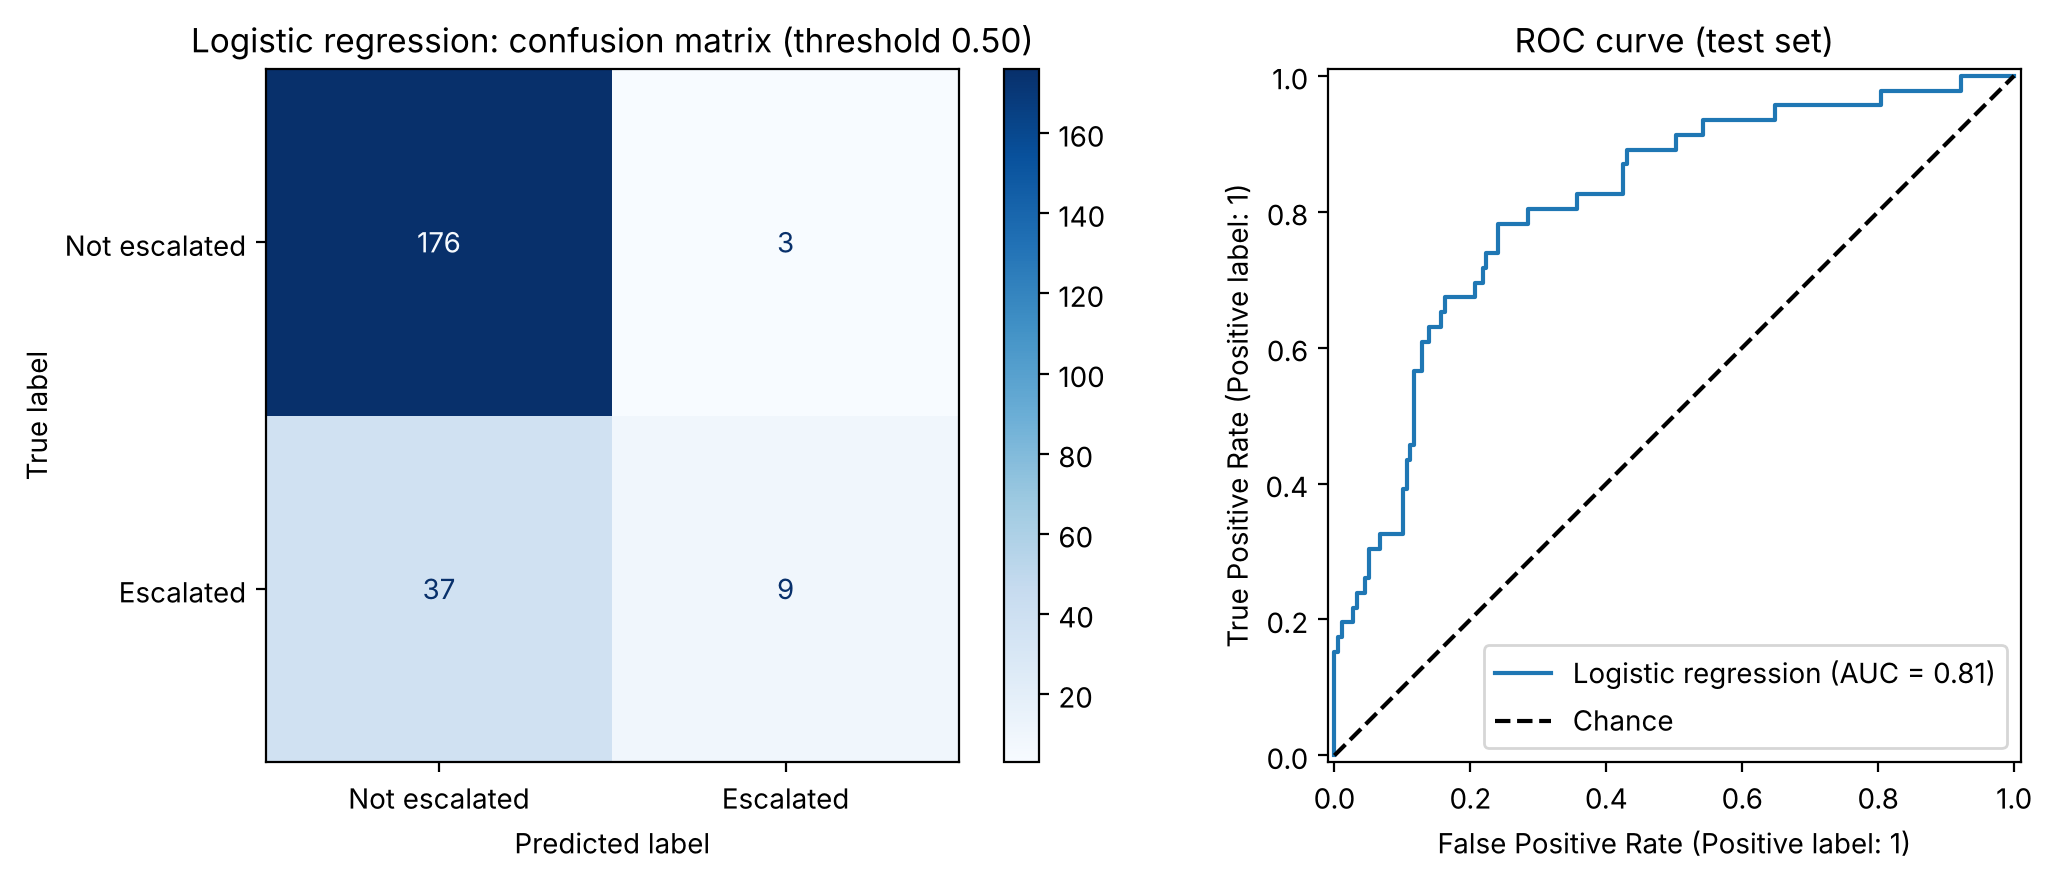

In [5]:
logit = fitted["Logistic regression"]
pred_lr = logit.predict(X_test)
proba_lr = logit.predict_proba(X_test)[:, 1]

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_lr, display_labels=["Not escalated", "Escalated"],
                                        cmap="Blues", ax=ax[0])
ax[0].set_title("Logistic regression: confusion matrix (threshold 0.50)")
RocCurveDisplay.from_predictions(y_test, proba_lr, name="Logistic regression", ax=ax[1])
ax[1].plot([0, 1], [0, 1], "k--", label="Chance")
ax[1].legend(); ax[1].set_title("ROC curve (test set)")
plt.tight_layout(); plt.show()

## 5. Threshold analysis and the 5×FN + 1×FP cost

In [6]:
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
rows = []
for t in thresholds:
    pred = (proba_lr >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"Threshold": t,
                 "Precision": precision_score(y_test, pred, zero_division=0),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred, zero_division=0),
                 "FP": fp, "FN": fn, "Cost (5*FN + FP)": 5*fn + fp})
thr = pd.DataFrame(rows).set_index("Threshold")
display(thr.round(3))
best_t = thr["Cost (5*FN + FP)"].idxmin()
print("Threshold with minimum cost:", best_t, "| cost =", thr.loc[best_t, "Cost (5*FN + FP)"])

,Precision,Recall,F1,FP,FN,Cost (5*FN + FP)
Threshold,,,,,,
0.2,0.429,0.783,0.554,48,10,98
0.3,0.549,0.609,0.577,23,18,113
0.4,0.571,0.261,0.358,9,34,179
0.5,0.750,0.196,0.310,3,37,188
0.6,1.000,0.065,0.122,0,43,215
0.7,0.000,0.000,0.000,0,46,230


Threshold with minimum cost: 0.2 | cost = 98


**What changes when the threshold is lowered?** The model labels more tickets as "escalate". **Recall rises** (fewer missed escalations, FN falls from 46 at 0.70 down to 10 at 0.20) while **precision falls** and **false positives rise** (0 at 0.60 up to 48 at 0.20). F1 peaks around 0.30 (0.577), but F1 weights FP and FN equally, so it is *not* the right yardstick when a miss costs 5 times a false alarm.

**Which threshold minimizes 5×FN + FP?** Among the required grid, **0.20** gives the lowest test cost (**98**: 10 FN × 5 + 48 FP), versus 113 at 0.30 and 188 at the default 0.50.

**Why this estimate may be optimistic:** the threshold was chosen by looking at the *same* test set that is then used to report its cost. With only 46 positives, each FN swings the cost by 5, so the minimum partly reflects noise ("winner's curse"). Reusing the test set repeatedly for tuning leaks information and makes the reported cost too good. The threshold should be selected on validation data or by cross-validation, and the final test set touched once.

## 6. Stratified 5-fold CV: tuning k for k-NN (scoring = F1)

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
knn_pipe = Pipeline([("prep", preprocess), ("model", KNeighborsClassifier())])
grid = GridSearchCV(knn_pipe, {"model__n_neighbors": [5, 9, 15, 21, 31]},
                    scoring="f1", cv=cv, return_train_score=False)
grid.fit(X_train, y_train)
cv_table = (pd.DataFrame({"k": grid.cv_results_["param_model__n_neighbors"].astype(int),
                          "mean CV F1": grid.cv_results_["mean_test_score"],
                          "std CV F1": grid.cv_results_["std_test_score"]}).set_index("k").round(3))
display(cv_table)
print("Best k:", grid.best_params_["model__n_neighbors"], "| best CV F1:", round(grid.best_score_, 3))

,mean CV F1,std CV F1
k,,
5,0.243,0.095
9,0.198,0.065
15,0.160,0.065
21,0.146,0.056
31,0.112,0.040


Best k: 5 | best CV F1: 0.243


Smaller k scored best (k = 5), with F1 falling steadily as k grows: larger k smooths the vote toward the majority class, so fewer escalations are flagged at a 0.5 cut-off. Even the best k-NN has a low CV F1 (0.243), well below the logistic regression and LDA test F1 of 0.31 at the same default cut-off, so tuning k does not change the model ranking.

## 7. Probability concepts and the cost-sensitive threshold

In [8]:
p = 0.30; c_fp, c_fn = 1, 5
cost_escalate = (1 - p) * c_fp          # we escalate; wrong when ticket would NOT escalate
cost_no_escalate = p * c_fn             # we do not escalate; wrong when it WOULD escalate
print(f"Expected cost of escalating     = (1 - 0.30) x 1 = {cost_escalate:.2f}")
print(f"Expected cost of NOT escalating =      0.30  x 5 = {cost_no_escalate:.2f}")
print(f"Cost-sensitive threshold p* = c_FP / (c_FP + c_FN) = {c_fp/(c_fp+c_fn):.4f}")

Expected cost of escalating     = (1 - 0.30) x 1 = 0.70
Expected cost of NOT escalating =      0.30  x 5 = 1.50
Cost-sensitive threshold p* = c_FP / (c_FP + c_FN) = 0.1667


**Bayes' rule in the ticket scenario.** Let *E* = "ticket escalates" and *x* = the observed ticket features (complexity, priority, channel, ...).

- **Prior P(E):** the base rate of escalation before looking at the ticket, about 0.21 here.
- **Likelihood P(x | E):** how typical these features are among tickets that *did* escalate (e.g. high complexity and a phone channel may be common among escalated tickets).
- **Evidence P(x):** how common these features are across *all* tickets, escalated or not: P(x|E)P(E) + P(x|¬E)P(¬E). It normalizes the result.
- **Posterior P(E | x) = P(x | E) P(E) / P(x):** the updated probability that *this* ticket escalates after seeing its features. This is what the classifier estimates.

**Expected-cost comparison at P(E|x) = 0.30 (FP cost 1, FN cost 5):**

- Escalate: we are wrong with probability 0.70 and pay the false-positive cost, so expected cost = 0.70 × 1 = **0.70**.
- Do not escalate: we are wrong with probability 0.30 and pay the false-negative cost, so expected cost = 0.30 × 5 = **1.50**.

Escalating is cheaper, so we escalate.

**Derivation of the threshold.** Escalate when its expected cost is lower: (1 − p)·c_FP < p·c_FN, which gives p > c_FP / (c_FP + c_FN) = 1/(1+5) = **1/6 ≈ 0.167**. A 0.50 threshold is only right when both errors cost the same. This is consistent with the empirical result: the best tested threshold (0.20) is close to 1/6. (This formula assumes well-calibrated probabilities, which should be verified.)

## 8. Recommendation (deployment)

**Model choice.** I recommend **logistic regression**. It ties with LDA on test precision, recall, F1 and ROC-AUC (about 0.81), clearly beats k-NN (AUC 0.70; best cross-validated F1 only 0.24 after tuning k), and is far better than the majority baseline, whose 79.6% accuracy hides zero recall. Logistic regression is also simple, fast, produces probabilities that can be thresholded, and its coefficients are easy to explain to support staff, which matters for trust and auditing.

**Threshold.** Do not use 0.50: at that cut-off the model misses 37 of 46 escalations (cost 188). With a miss costing five times a false alarm, decision theory points to a threshold of 1/6 ≈ 0.17, and the empirical test agrees that a low cut-off is best: **0.20** gave the lowest cost (98), with recall 0.78 and precision 0.43 (10 FN, 48 FP). I would deploy at roughly 0.17 to 0.20 and review it periodically.

**Error costs.** The 5:1 ratio is only illustrative. A false positive wastes an agent's time on a ticket that would have resolved; a false negative lets a serious ticket sit unescalated, with customer and reputational harm. Real costs should be measured with the business and the threshold recomputed as c_FP / (c_FP + c_FN).

**Limitations.** The data are synthetic and small (900 tickets, only 46 escalations in the test set), so every estimate is noisy: one extra miss changes the cost by 5. The threshold was selected on the test set, so the reported cost is optimistic; it should be re-tuned with cross-validation and then confirmed on fresh data. Probabilities may be poorly calibrated, which weakens the 1/6 rule. Discrimination is only moderate (AUC about 0.81), and some inputs had imputed values.

**Responsible use.** The model should support, not replace, human judgement: staff should be able to override it. Monitor for drift and for unequal error rates across channels, priorities or customer tenure groups, because a model that under-escalates some customers can cause unfair service. Avoid using features that proxy for protected characteristics, document the model and costs, and track false negatives continuously.

**Further checks before deployment:** calibration curves, threshold tuning by cross-validation, a fresh hold-out or time-based validation set, subgroup error analysis, a shadow-mode pilot against real tickets, and confidence intervals on recall and cost.